# Task 2 - Clustering

In [314]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
from IPython.display import display

In [315]:
data = pd.read_pickle("clean_data.pkl")
data.head(3)

,url,name,price,brand,motor_power_w,battery_capacity_wh,range_km,speed_kmh,color
0,https://www.geekbuying.com/item/Ausom-L1-Elect...,"Ausom L1 Electric Scooter, 800W Motor, 48V 15....",10656.98,ausom,500.0,998.4,90.0,20.0,NaN
1,https://www.geekbuying.com/item/Kukirin-G2-Fol...,Kukirin G2 Foldable Electric Scooter 2026 Upgr...,11870.77,kukirin,800.0,NaN,55.0,45.0,NaN
2,https://www.geekbuying.com/item/BOYUEDA-Q7-Pro...,"BOYUEDA Q7 Pro Max Electric Scooter, 1600W*2 M...",18910.69,boyueda,3200.0,1456.0,100.0,70.0,NaN


# 1 Nerelevantní data

nejsou relevantní `url`, `name` - jsou jenom informativní pro lidí, ne pro statistický model

In [316]:
data = data.drop(columns=["url", "name"])

# 2 Chybějící hodnoty

- Z explorativní analýzy víme, že jsou tam data s 6 a více chybějícími hodnotami - ty odstraníme
- Další způsoby si poradit s chybějícími hodnotami:
1. Vyměnit na novou kategorii např. "nan"/"unknown"
2. Vyměnit na nečastější/matematicky očekávanou hodnotu (kategorii)


In [317]:
data["brand"] = data["brand"].cat.add_categories(["Unknown"]).fillna("Unknown")
data["color"] = data["color"].fillna(data["color"].mode()[0])

In [318]:
numeric_columns = ["price", "motor_power_w", "battery_capacity_wh", "range_km", "speed_kmh"]

# Runs later. affects IQR iteration
def fill_missing_numeric_values():
    global data
    data[numeric_columns] = data[numeric_columns].fillna(
        data[numeric_columns].median()
    )

# 3 Odlehlé hodnoty

zbavíme se všech numerických hodnot iterativním odstraněním odléhlých hodnot s `1.5 * IQR`; tím nám zůstanou maximálně věrohodná data

Rows before removing: 334

price                  17945.0525
motor_power_w            500.0000
battery_capacity_wh      329.4000
range_km                  45.0000
speed_kmh                 15.0000
dtype: float64

Rows after removing: 124


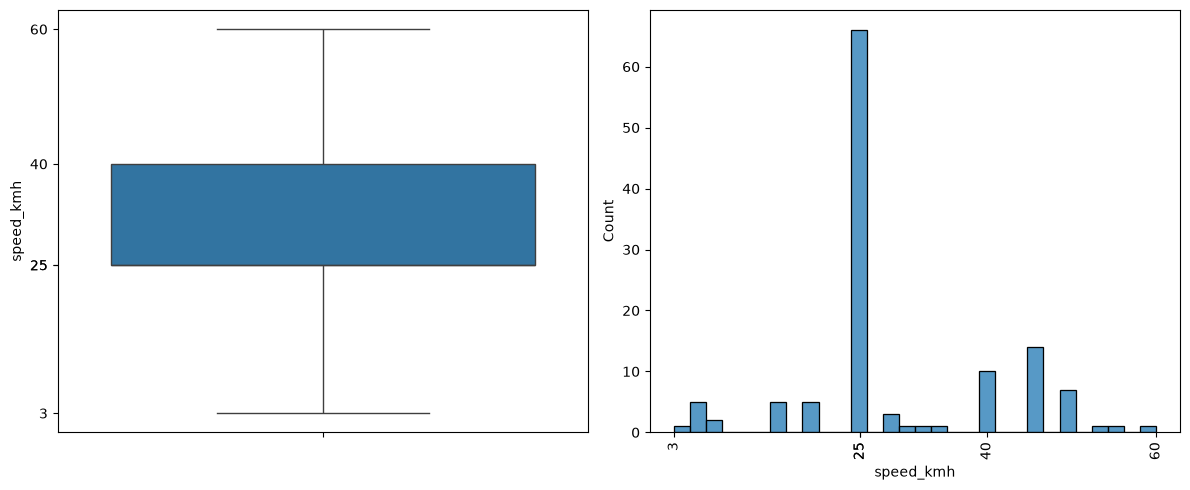

In [319]:
def plot_speed_distribution(data):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    speed = data["speed_kmh"].dropna()

    sns.boxplot(y=speed, ax=axes[0])
    speed_ticks = speed.describe()[["min", "25%", "50%", "75%", "max"]].to_numpy()
    axes[0].set_yticks(speed_ticks)
    axes[0].set_yticklabels([f"{value:,.0f}" for value in speed_ticks])

    sns.histplot(x=speed, bins=30, ax=axes[1])
    axes[1].set_xticks(speed_ticks)
    axes[1].set_xticklabels([f"{value:,.0f}" for value in speed_ticks])
    axes[1].tick_params(axis="x", labelrotation=90)

    fig.tight_layout()
    plt.show()

def get_rid_of_price_outliers():
    global data

    while True:
        q1 = data[numeric_columns].quantile(0.25)
        q3 = data[numeric_columns].quantile(0.75)
        iqr = q3 - q1
        lower_bounds = q1 - 1.5 * iqr
        upper_bounds = q3 + 1.5 * iqr
        within_bounds = (
            data[numeric_columns].notna().all(axis=1)
            & data[numeric_columns].ge(lower_bounds).all(axis=1)
            & data[numeric_columns].le(upper_bounds).all(axis=1)
        )

        filtered_data = data.loc[within_bounds]
        if len(filtered_data) == len(data):
            break
        data = filtered_data

    print(iqr, end="\n\n")


print(f"Rows before removing: {len(data)}", end="\n\n")
get_rid_of_price_outliers()
print(f"Rows after removing: {len(data)}")
plot_speed_distribution(data)

In [320]:
fill_missing_numeric_values()

# 4 Diskretizace numerických atributů

In [321]:
labels = {
    "motor_power_w"      : ["low", "medium", "high"],
    "battery_capacity_wh": ["small", "medium", "large"],
    "range_km"           : ["short", "medium", "long"],
    "speed_kmh"          : ["slow", "medium", "fast"],
    "price"              : ["low", "medium", "high"]
}

for numeric_column in numeric_columns:
    column = data[numeric_column]

    bins = sorted(set([
        column.min(),
        column.quantile(0.5),
        column.quantile(0.75),
        float("inf")
    ]))

    column_labels = labels[numeric_column][:len(bins) - 1]

    data[numeric_column] = pd.cut(
        column,
        bins=bins,
        labels=column_labels,
        include_lowest=True
    ).astype("category")

<class 'pandas.DataFrame'>
Index: 124 entries, 0 to 328
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   price                124 non-null    category
 1   brand                124 non-null    category
 2   motor_power_w        124 non-null    category
 3   battery_capacity_wh  124 non-null    category
 4   range_km             124 non-null    category
 5   speed_kmh            124 non-null    category
 6   color                124 non-null    category
dtypes: category(7)
memory usage: 5.9 KB
None


,price,brand,motor_power_w,battery_capacity_wh,range_km,speed_kmh,color
0,low,ausom,low,large,long,slow,black
7,low,geleipu,high,large,medium,slow,black
8,low,kukirin,high,large,medium,slow,black
12,low,twofish,low,small,short,medium,blue
18,medium,randride,high,medium,short,fast,black


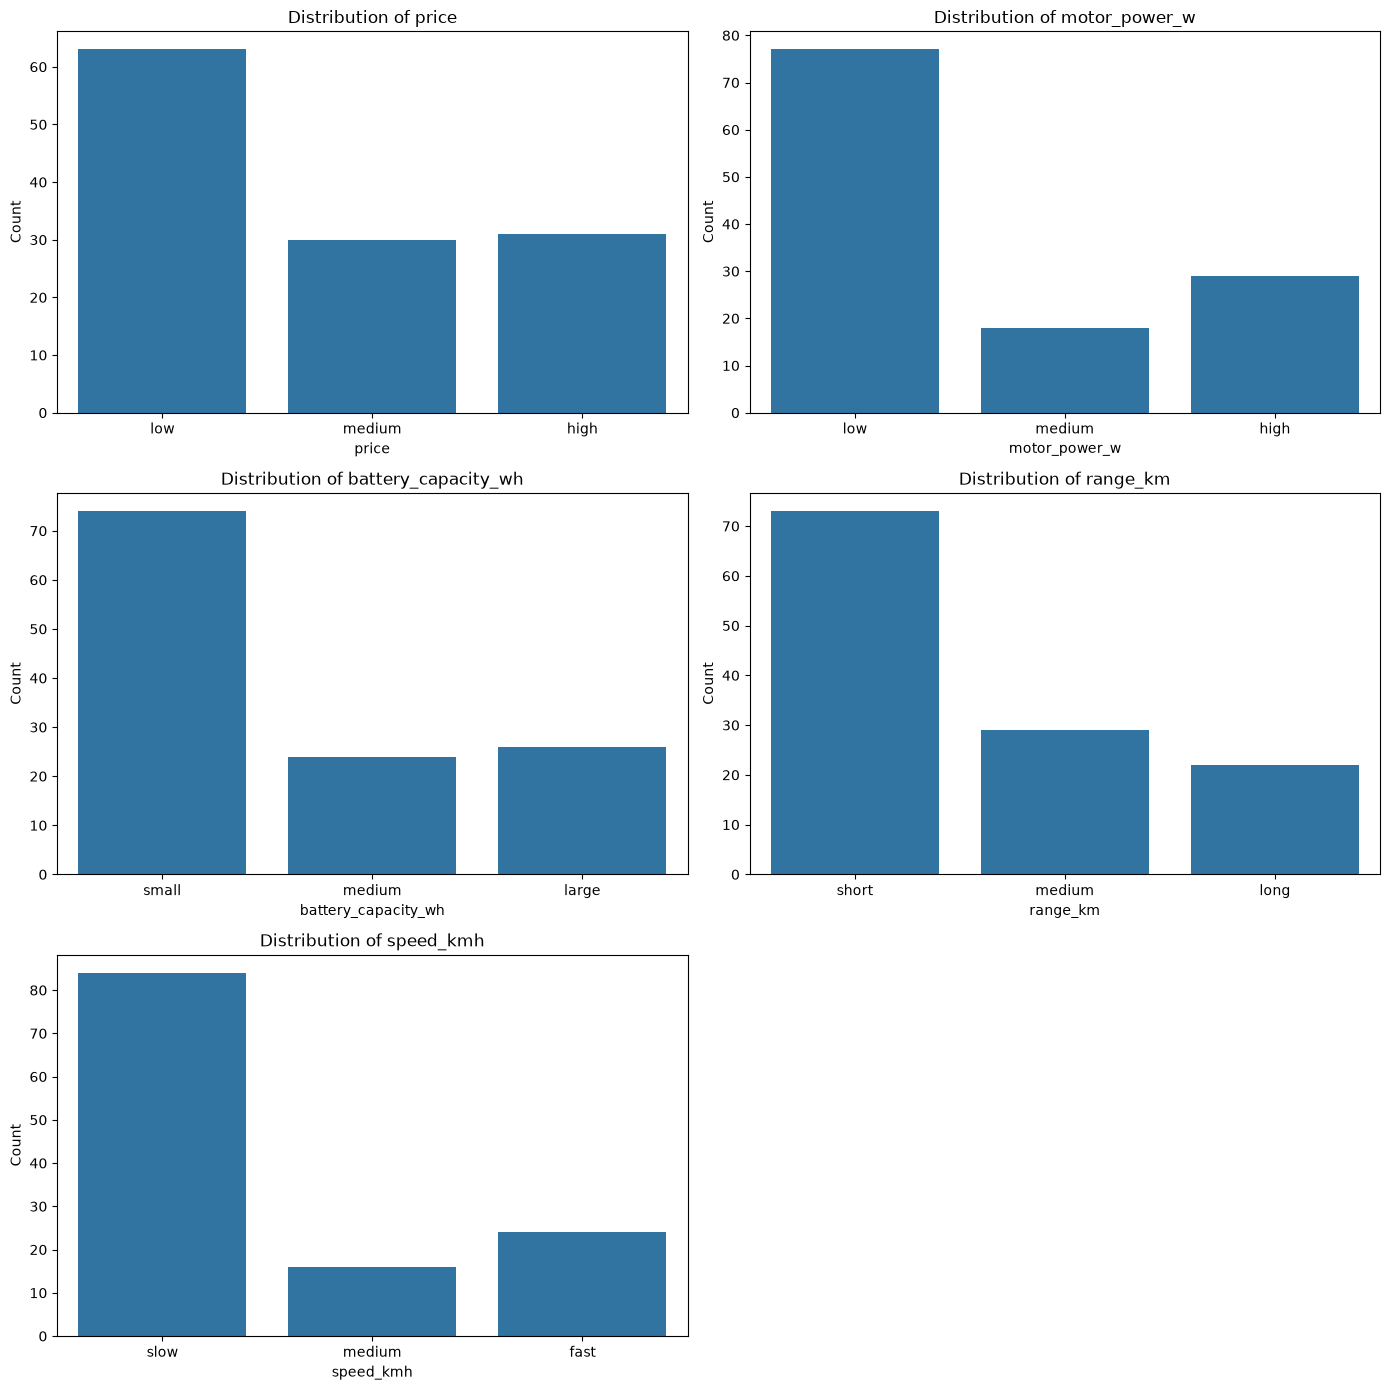

In [322]:
def draw_barplots(data):
    fig, axes = plt.subplots(3, 2, figsize=(14, 14))

    for axis, numeric_column in zip(axes.flat, numeric_columns):
        counts = data[numeric_column].value_counts().reindex(labels[numeric_column], fill_value=0)
        sns.barplot(x=counts.index, y=counts.values, ax=axis)
        axis.set_title(f"Distribution of {numeric_column}")
        axis.set_ylabel("Count")

    axes.flat[-1].set_visible(False)
    fig.tight_layout()
    plt.show()


print(data.info())
display(data.head(5))
draw_barplots(data)

In [323]:
data.to_csv("cluster_data.csv", index=False)
print("Saved cluster_data.csv")

Saved cluster_data.csv
